# 현실의 데이터 22: 도로 교통 속도 예측 (내비)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/22_traffic_speed.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 내비게이션 · 도착시간 · 시공간 그래프 · 교통 관제

> 샌프란시스코 베이 지역 고속도로 센서 325개. 15분 뒤 이 구간은 막힐까?

**데이터**: PEMS-BAY (시험 기간) (약 100MB). Li et al. (2018). 캘리포니아 교통국 PeMS 의 베이 지역 고속도로 센서 325개, 5분 간격 평균 속도 (mph), 2017년 1~6월. 빈칸이 거의 없다 (같은 논문의 METR-LA 는 12%). 센서 위치 · 도로 거리로 만든 연결 그래프 포함 (Hugging Face witgaw/PEMS-BAY, 시험 기간 2017-05-25 ~ 06-30 만 받는다).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 센서 × 5분 |
| ② 입력 X | 그 센서의 지난 1시간 속도 + 이웃 센서 속도 + 시각 |
| ③ 출력 y | 15분 뒤 속도 (mph) |
| ④ 평가지표 | MAE (mph), 막힘 (< 40 mph) 재현율 |
| ⑤ 기준선 | 지금 속도 그대로 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Li et al. (2018) Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting, ICLR (METR-LA · PEMS-BAY)](https://arxiv.org/abs/1707.01926)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

데이터가 이미 '지난 12칸 (1시간) → 다음 12칸' 창으로 잘려 있다. 필요한 열만 읽는다. 속도 0 은 '센서 고장 · 빈칸' 인데, 이 데이터에는 거의 없다 (1주 3차시의 결측치 걱정이 적은 데이터).

In [2]:
BASE = "https://huggingface.co/datasets/witgaw/PEMS-BAY/resolve/main/"
cols = ["node_id", "t0_timestamp", "x_t+0_d1"] + [f"x_t-{k}_d0" for k in range(11, 0, -1)] + ["x_t+0_d0", "y_t+3_d0"]
df = pd.read_parquet(download(BASE + "test.parquet", "data/pemsbay_test.parquet"), columns=cols)
loc = pd.read_csv(download(BASE + "sensor_graph/sensor_locations.csv", "data/pemsbay_locations.csv"))
df["time"] = pd.to_datetime(df["t0_timestamp"])
print(df.shape, df["time"].min(), "~", df["time"].max(), "| sensors", df["node_id"].nunique())
print(f"zero (missing) speeds now: {(df['x_t+0_d0'] == 0).mean():.3%}")
loc.head(3)

(3386175, 17) 2017-05-25 18:45:00 ~ 2017-06-30 22:55:00 | sensors 325
zero (missing) speeds now: 0.006%


,sensor_id,latitude,longitude
0,400001,37.364085,-121.901149
1,400017,37.253303,-121.945440
2,400030,37.359087,-121.906538


## 열어 보기: 지도와 일주일의 속도

센서 위치를 지도 위에 찍고 (배경 지도: Esri World Light Gray Canvas), 하루 속도가 가장 크게 출렁이는 센서의 일주일을 본다. 출퇴근 시간에 푹 꺼질까?

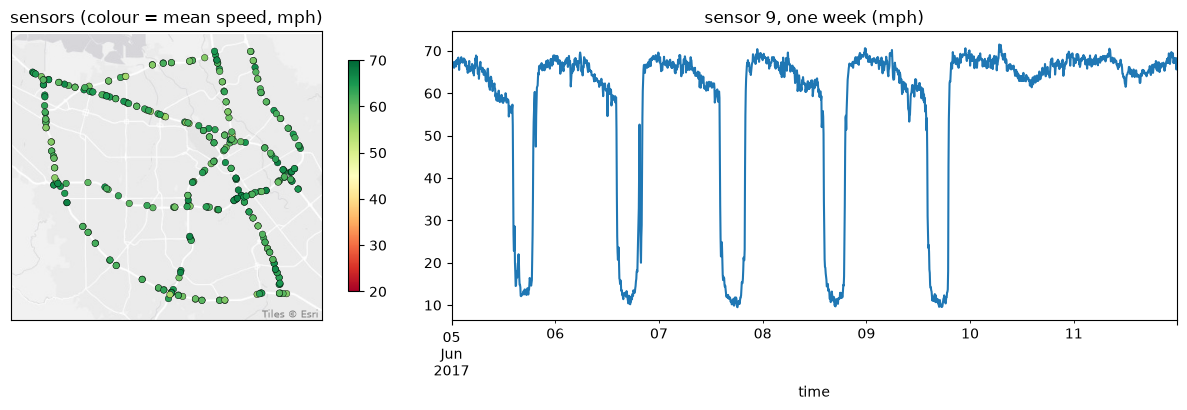

In [3]:
import math
from PIL import Image

def to_merc(lat, lon):
    """Latitude/longitude (degrees) -> Web Mercator metres"""
    R = 6378137.0
    return R * np.radians(lon), R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))

def add_basemap(ax, lat, lon, zoom=11, alpha=0.85):
    """Draw light map tiles (Esri World Light Gray Canvas) under points given in Web Mercator"""
    n = 2 ** zoom
    tx = lambda lo: int((lo + 180) / 360 * n)
    ty = lambda la: int((1 - math.asinh(math.tan(math.radians(la))) / math.pi) / 2 * n)
    x0, x1, y0, y1 = tx(lon.min()), tx(lon.max()), ty(lat.max()), ty(lat.min())
    img = Image.new("RGB", ((x1 - x0 + 1) * 256, (y1 - y0 + 1) * 256))
    for x in range(x0, x1 + 1):
        for y in range(y0, y1 + 1):
            tile = download(f"https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{zoom}/{y}/{x}", f"data/tiles/esri_{zoom}_{x}_{y}.jpg")
            img.paste(Image.open(tile).convert("RGB"), ((x - x0) * 256, (y - y0) * 256))
    size = 2 * math.pi * 6378137.0 / n
    left, top = -math.pi * 6378137.0 + x0 * size, math.pi * 6378137.0 - y0 * size
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    ax.imshow(img, extent=(left, left + img.width / 256 * size, top - img.height / 256 * size, top), alpha=alpha, zorder=0)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.text(0.99, 0.01, "Tiles © Esri", transform=ax.transAxes, ha="right", fontsize=7, color="gray")

def plot_sensors(ax, loc, values, title):
    """Sensors on a map, coloured by speed"""
    mx, my = to_merc(loc["latitude"].values, loc["longitude"].values)
    sc = ax.scatter(mx, my, c=values, cmap="RdYlGn", vmin=20, vmax=70, s=22, edgecolors="black", linewidths=0.3, zorder=2)
    ax.margins(0.08); add_basemap(ax, loc["latitude"], loc["longitude"])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    return sc

speed = df.pivot(index="time", columns="node_id", values="x_t+0_d0").replace(0, np.nan)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
sc = plot_sensors(axs[0], loc, speed.mean().reindex(range(len(loc))).values, "sensors (colour = mean speed, mph)")
plt.colorbar(sc, ax=axs[0], shrink=0.8)
node = speed.groupby(speed.index.hour).mean().std().idxmax()      # the sensor whose speed swings most over a day
speed.loc["2017-06-05":"2017-06-11", node].plot(ax=axs[1], title=f"sensor {node}, one week (mph)")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 지금까지 → 15분 뒤 속도

**시간 순서**: 앞 70% 기간 학습, 뒤 30% 시험. 빈칸 (0) 인 행은 뺀다 (거의 없다).
- 기준선: 지금 속도 그대로
- 모델 1: 그 센서의 지난 1시간 속도 12개 + 시각 → 선형회귀
- 모델 2: 모델 1 + **연결 그래프의 이웃 센서들 평균 속도** (13주차 그래프 신경망의 아이디어)

In [4]:
from sklearn.linear_model import LinearRegression

adj = np.load(download(BASE + "sensor_graph/adj_mx.npy", "data/pemsbay_adj.npy"), allow_pickle=True)
adj = adj[2] if adj.dtype == object else adj                  # some versions store (ids, id_map, matrix)
W = np.asarray(adj, dtype=float); np.fill_diagonal(W, 0); W = W / np.maximum(W.sum(1, keepdims=True), 1e-9)
neigh = pd.DataFrame(np.nan_to_num(speed.values) @ W.T / np.maximum((~speed.isna()).values @ (W.T > 0), 1), index=speed.index, columns=speed.columns)
df["neigh"] = neigh.stack().reindex(pd.MultiIndex.from_arrays([df["time"], df["node_id"]])).values

lags = [f"x_t-{k}_d0" for k in range(11, 0, -1)] + ["x_t+0_d0"]
d = df[(df[lags + ["y_t+3_d0"]] > 0).all(axis=1)].copy()
cut = d["time"].quantile(0.7); tr, te = d[d["time"] <= cut], d[d["time"] > cut]
y = te["y_t+3_d0"].values; jam = y < 40
print(f"test rows {len(te):,} | jams (<40 mph) {jam.mean():.1%}")
for name, cols_ in [("now", None), ("own past hour + time", lags + ["x_t+0_d1"]), ("+ neighbours", lags + ["x_t+0_d1", "neigh"])]:
    pred = te["x_t+0_d0"].values if cols_ is None else LinearRegression().fit(tr[cols_], tr["y_t+3_d0"]).predict(te[cols_])
    print(f"{name:22s} MAE {np.mean(np.abs(pred - y)):.2f} mph   jam (<40) recall {np.mean(pred[jam] < 40):.0%}")

test rows 1,014,975 | jams (<40 mph) 6.2%
now                    MAE 1.70 mph   jam (<40) recall 85%
own past hour + time   MAE 1.75 mph   jam (<40) recall 82%


+ neighbours           MAE 1.75 mph   jam (<40) recall 82%


**관찰**: 15분 뒤는 '지금 그대로' 가 이긴다 (MAE 1.70 대 1.75 mph). 지난 한 시간 · 이웃 센서를 넣은 선형회귀가 오히려 조금 나쁘다. 15분은 너무 가까워서 지금 속도가 거의 답이고, 선형회귀는 제곱 오차를 줄이도록 배워 MAE 로 재면 손해를 보기도 한다. 기준선을 먼저 재지 않았다면 '모델을 만들었다' 고 착각했을 것이다. 목표를 1시간 뒤 (`y_t+12_d0`) 로 바꾸고 다시 해 보자. 그래프 신경망 (13주차, DCRNN) 은 '어느 이웃이 얼마나 중요한지' 까지 배운다.

## 다른 문제로 바꿔 보기

- **빈칸이 많은 데이터로**: 같은 논문의 METR-LA (로스앤젤레스, 속도 0 이 12%) 로 바꿔 보자. `BASE` 의 `PEMS-BAY` 를 `METR-LA` 로만 고치면 된다. 빈칸을 빼는 것과 채우는 것, 어느 쪽이 나을까?
- **도착 시간 (ETA)**: 한 행 = 출발지 → 도착지 길 하나, 출력 = 걸리는 분. 길 위 센서들의 예측 속도를 이어 붙인다.
- 사고 · 공사 같은 '이벤트' 는 과거 속도에 없다. 무엇을 입력에 더해야 할까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |